<a href="https://colab.research.google.com/github/vijay-negi07/mnist-dataset/blob/main/mnist_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import urllib.request
from io import BytesIO

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

response = urllib.request.urlopen(url)
file_data = response.read()

with np.load(BytesIO(file_data)) as data:
    x_train = data["x_train"]
    y_train = data["y_train"]
    x_test = data["x_test"]
    y_test = data["y_test"]

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
#Check the shape of the dataset
print("Training image shape : ", x_train.shape)
print("Training labels shape : ",y_train.shape)

Training image sahpe :  (60000, 28, 28)
Training labels shape :  (60000,)


In [ ]:
#Checking the testing dataset
print("Testing image shape : ", x_test.shape)
print("Testing labels shape : ", y_test.shape)

Testing image shape :  (10000, 28, 28)
Testing labels shape :  (10000,)


In [ ]:
#Check data types and pixel value range
print("Data type of images : ", x_train.dtype)
print("Data type of labels : ",y_train.dtype)
print("Minimum pixel value : ",x_train.min())
print("Maximum pixel value : ",x_train.max())

Data type of images :  uint8
Data type of labels :  uint8
Minimum pixel value :  0
Maximum pixel value :  255


In [25]:
#Checking missing values in training images and testing images
print("Missing values in training images:",np.isnan(x_train).sum())
print("Missing values in training labels:",np.isnan(y_train).sum())
print("Missing values in testing images:",np.isnan(x_test).sum())
print("Missing values in testing labels:",np.isnan(y_test).sum())

Missing values in training images: 0
Missing values in training labels: 0
Missing values in testing images: 0
Missing values in testing labels: 0


In [ ]:
# Check duplicate images in training dataset

unique_images = np.unique(x_train.reshape(60000, -1), axis=0)
duplicate_count = len(x_train) - len(unique_images)
print("Total training images:", len(x_train))
print("Unique training images:", len(unique_images))
print("Duplicate images:", duplicate_count)

Total training images: 60000
Unique training images: 60000
Duplicate images: 0


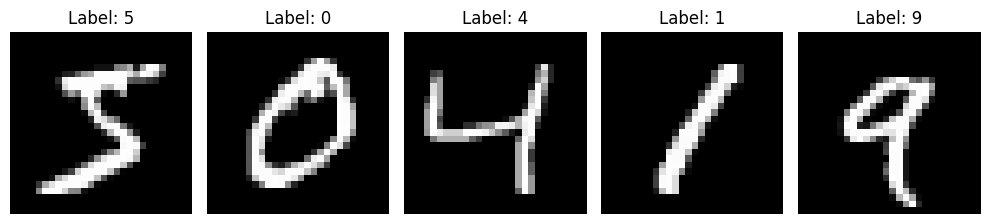

In [ ]:
#Display the first 5 images
plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#Normalize training and testing images

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())
print("Testing data minimum:", x_test.min())
print("Testing data maximum:", x_test.max())


Minimum pixel value: 0.0
Maximum pixel value: 1.0
Testing data minimum: 0.0
Testing data maximum: 1.0


In [ ]:
#Reshaping

x_train = x_train.reshape(x_train.shape[0], 784)
x_test = x_test.reshape(x_test.shape[0],784)
print("Trainig shape : ", x_train.shape)
print("Testing shape : ", x_test.shape)

Trainig shape :  (60000, 784)
Testing shape :  (10000, 784)


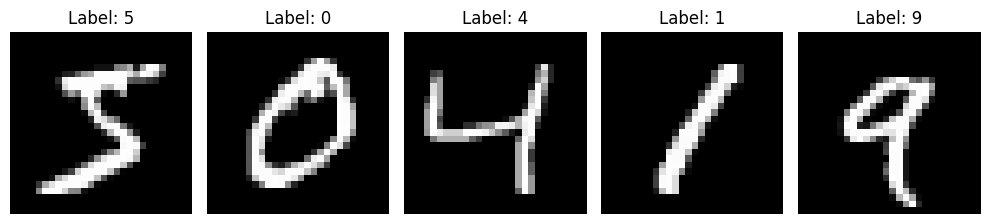

In [ ]:

plt.figure(figsize=(10, 3))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
import cv2

In [ ]:
#Rotation
image = x_train[0].reshape(28, 28)
height, width = image.shape
center = (width // 2, height // 2)

matrix = cv2.getRotationMatrix2D(center, 15, 1.0)
rotated_image = cv2.warpAffine(image, matrix, (width, height))

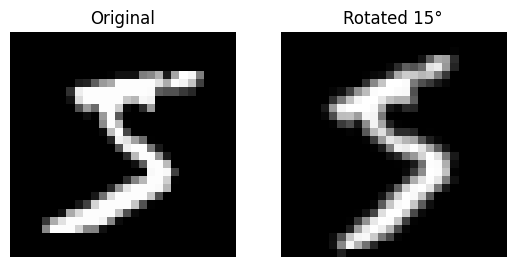

In [ ]:
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated_image, cmap="gray")
plt.title("Rotated 15°")
plt.axis("off")

plt.show()

In [ ]:
#image shifting
height,width = image.shape
matrix = np.float32([[1,0,5],[0,1,3]])
shifted_image = cv2.warpAffine(image,matrix, (width, height))

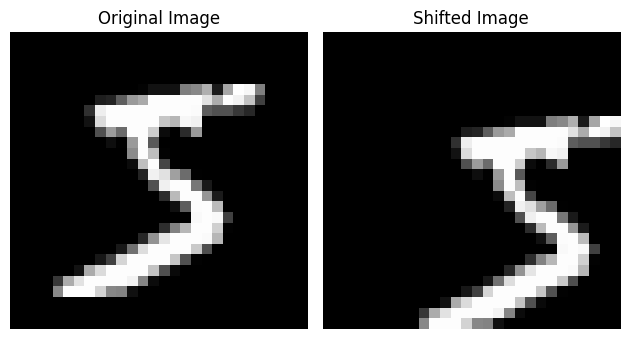

In [ ]:
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(shifted_image, cmap="gray")
plt.title("Shifted Image")
plt.axis("off")

plt.tight_layout()
plt.show()

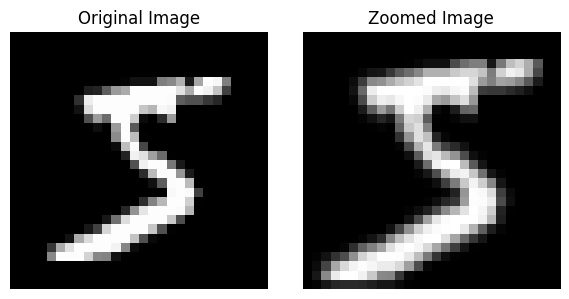

In [27]:
# Zooming

image = x_train[0].reshape(28, 28)
height, width = image.shape
center = (width // 2, height // 2)

# Zooming in by 20%
matrix = cv2.getRotationMatrix2D(center, 0, 1.2)

zoomed_image = cv2.warpAffine(
    image, matrix, (width, height)
)

# Display original and zoomed images
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(zoomed_image, cmap="gray")
plt.title("Zoomed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

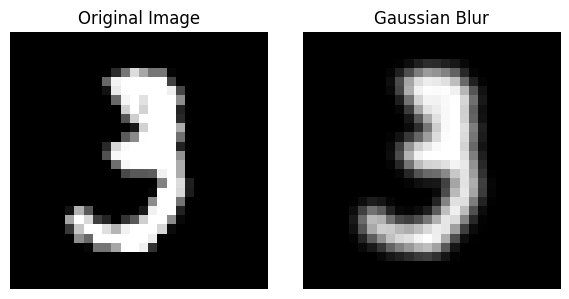

In [29]:
#Gaussian Blur

image = x_train[10].reshape(28, 28)

blurred_image = cv2.GaussianBlur(image, (3, 3), 0)

# Displaying original and blurred images
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_image, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

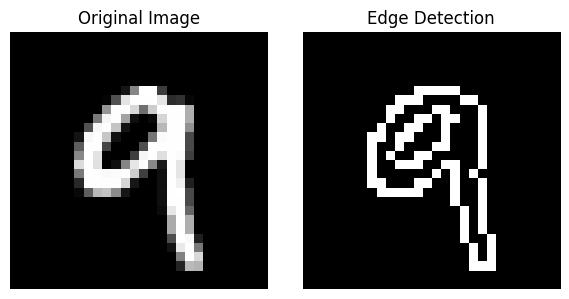

In [30]:
#Edge Detection
image = x_train[110].reshape(28, 28)

edges = cv2.Canny(image, 50, 150)

# Displaying original and edge-detected images
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()